# 1단계 — 파이프라인 모듈화 + 평가기간 점검

- **모듈화**: `run_variable_pipeline(var)` 하나로 "16개 후보 백테스트 -> CRPS(리샘플링)+bootstrap -> 결정규칙 -> 커버리지 체크"가 전부 도는 함수를 만든다(5-1 로직 재사용).
- **평가기간**: 현재 백테스트가 몇 년치인지 확인하고, origin을 늘리면 생기는 장단점을 실험한다.
- **대표변수**: `X3_l1`(GP-Matern 함정 케이스 포함 -- 모듈 검증에 가장 까다로움)
- **안전장치**(5-1과 동일): bootstrap 마진, 최대오차 체크, 커버리지<60% 시 E3 복귀

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import properscoring as ps

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}
H = 4
INITIAL_CALIB = 15
MIN_TRAIN = 20
LAG = 2
E3 = ["arima_aic", "gp_matern", "gp_rbf"]

TARGET_VAR = "X3_l1"

FAMILY_LABELS = {
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "theta": "시계열-Theta",
    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear",
    "naive": "baseline (naive)", "gbm_lag": "트리기반 (GBM)",
    "rf_lag": "트리기반 (RandomForest)", "knn_lag": "k-NN", "holt_damped": "시계열-Holt(감쇠추세)",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)

err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")   # 11개 모델 (5-1과 동일 캐시)
err_32 = pd.read_pickle("../cache/cache_nb3_2_err_df.pkl")   # naive, gbm_lag
extra = err_32[err_32["model"].isin(["naive", "gbm_lag"])]
BASE_ERR_DF = pd.concat([err_42, extra], ignore_index=True)  # 13개 모델(캐시로 이미 존재)


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


print(f"베이스 캐시 모델 {BASE_ERR_DF['model'].nunique()}개, 변수 {BASE_ERR_DF['var'].nunique()}개 로드 완료")
print(f"대표변수: {LABELS[TARGET_VAR]} ({TARGET_VAR})")


베이스 캐시 모델 13개, 변수 6개 로드 완료
대표변수: X3 (X3_l1)


## 1. 모듈화 -- 단일 변수용 파이프라인

1. `build_err_df_for(var)` -- 캐시 13개 모델 + 신규 RF/Holt/kNN으로 16개 후보 완성
2. `run_variable_pipeline(var)` -- CRPS(리샘플링)→bootstrap→결정규칙→커버리지 체크를 한 번에 실행

In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y


def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)


def fc_rf(values, h=H):
    return _recursive_forecast(lambda X, y: RandomForestRegressor(n_estimators=200, max_depth=4, random_state=0).fit(X, y), values, h)


def fc_knn(values, h=H):
    return _recursive_forecast(lambda X, y: KNeighborsRegressor(n_neighbors=3).fit(X, y), values, h)


def fc_holt(values, h=H):
    fit = ExponentialSmoothing(values, trend="add", damped_trend=True, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(h))


NEW_FUNCS = {"rf_lag": fc_rf, "knn_lag": fc_knn, "holt_damped": fc_holt}


def backtest_new_models(var, min_train=MIN_TRAIN, h=H):
    vals = raw[["quarter", var]].dropna()[var].values.astype(float)
    rows = []
    for origin in range(min_train, len(vals) - h + 1):
        train, actual = vals[:origin], vals[origin:origin + h]
        for name, fn in NEW_FUNCS.items():
            try:
                fc = fn(train, h)
            except Exception:
                fc = np.repeat(train[-1], h)
            err = actual - fc
            for hh in range(1, h + 1):
                rows.append({"var": var, "model": name, "origin": origin, "h": hh,
                             "err_t": err[hh - 1], "fc_t": fc[hh - 1], "actual_orig": actual[hh - 1]})
    return pd.DataFrame(rows)


def build_err_df_for(var, min_train=MIN_TRAIN, h=H):
    base = BASE_ERR_DF[BASE_ERR_DF["var"] == var].copy()
    new = backtest_new_models(var, min_train, h)
    combined = pd.concat([base, new], ignore_index=True)
    n_models = combined["model"].nunique()
    print(f"[{LABELS.get(var, var)}] err_df 완성 -- {n_models}개 모델(캐시 13 + 신규 3)")
    return combined


In [3]:
def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]


def run_variable_pipeline(var, err_df_v=None, min_train=MIN_TRAIN, initial_calib=INITIAL_CALIB, h=H,
                           margin_winrate=60.0, gap_over_e3=20.0, max_err_tolerance=1.2, coverage_floor=60.0,
                           n_boot=500, block_len=4, verbose=True):
    if err_df_v is None:
        err_df_v = build_err_df_for(var, min_train, h)

    candidates = list(FAMILY_LABELS.keys())

    def crps_components(name):
        rng = rng_for(name)
        e = err_df_v[err_df_v["model"] == name]
        origins = sorted(e["origin"].unique())
        var_std = e["actual_orig"].std()
        rows = []
        for i in range(initial_calib, len(origins)):
            calib = e[e["origin"].isin(origins[:i])]
            test = e[e["origin"] == origins[i]]
            crps_hs, errs_hs = [], []
            for hh in range(1, h + 1):
                calib_resid_h = calib[calib["h"] == hh]["err_t"].values
                row = test[test["h"] == hh].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std)
                errs_hs.append(abs(row["err_t"]) / var_std)
            rows.append({"origin": origins[i], "crps": np.mean(crps_hs), "abs_err": np.mean(errs_hs)})
        return pd.DataFrame(rows)

    def ensemble_crps_components(models, n_each=200):
        rngs = {m: rng_for(m) for m in models}
        sub = {m: err_df_v[err_df_v["model"] == m] for m in models}
        var_std = sub[models[0]]["actual_orig"].std()
        origins = sorted(sub[models[0]]["origin"].unique())
        rows = []
        for i in range(initial_calib, len(origins)):
            crps_hs, errs_hs = [], []
            for hh in range(1, h + 1):
                pooled, actual_orig, fc_mean = [], None, []
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == hh]["err_t"].values
                    row = test[test["h"] == hh].iloc[0]
                    actual_orig = row["actual_orig"]
                    fc_mean.append(row["fc_t"])
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each, replace=True)
                    pooled.append(samples)
                samples_all = np.concatenate(pooled)
                crps_hs.append(ps.crps_ensemble(actual_orig, samples_all) / var_std)
                errs_hs.append(abs(actual_orig - np.mean(fc_mean)) / var_std)
            rows.append({"origin": origins[i], "crps": np.mean(crps_hs), "abs_err": np.mean(errs_hs)})
        return pd.DataFrame(rows)

    pre = {name: crps_components(name) for name in candidates}
    pre["E3"] = ensemble_crps_components(E3)
    names = candidates + ["E3"]

    origins_v = sorted(pre[names[0]]["origin"].unique())
    rng = np.random.default_rng(hash(var) % (2**32))
    win_counts = {n: 0 for n in names}
    rank_sums = {n: 0.0 for n in names}
    for _ in range(n_boot):
        resampled = block_resample(origins_v, block_len, rng)
        means = {n: pre[n].set_index("origin").loc[resampled, "crps"].mean() for n in names}
        order = sorted(names, key=lambda n: means[n])
        win_counts[order[0]] += 1
        for rank, n in enumerate(order, start=1):
            rank_sums[n] += rank

    rows = []
    for n in names:
        sub = pre[n]
        rows.append({
            "모델": FAMILY_LABELS.get(n, n), "_key": n,
            "CRPS(평균)": round(sub["crps"].mean(), 4),
            "최대오차(정규화)": round(sub["abs_err"].max(), 4),
            "1위 비율(%)": round(100 * win_counts[n] / n_boot, 1),
            "평균 순위": round(rank_sums[n] / n_boot, 2),
        })
    summary = pd.DataFrame(rows).sort_values("1위 비율(%)", ascending=False).reset_index(drop=True)

    e3_row = summary[summary["_key"] == "E3"].iloc[0]
    best = summary.iloc[0]
    chosen, reason = "E3(공용모델 유지)", "뚜렷한 대체 후보 없음"
    if best["_key"] != "E3":
        winrate_ok = (best["1위 비율(%)"] >= margin_winrate) or (best["1위 비율(%)"] - e3_row["1위 비율(%)"] >= gap_over_e3)
        maxerr_ok = best["최대오차(정규화)"] <= e3_row["최대오차(정규화)"] * max_err_tolerance
        if winrate_ok and maxerr_ok:
            chosen = best["모델"]
            reason = f"1위비율 {best['1위 비율(%)']}%(E3 {e3_row['1위 비율(%)']}%), 최대오차 {best['최대오차(정규화)']}(E3 {e3_row['최대오차(정규화)']})"
        elif winrate_ok:
            reason = "1위비율은 앞서지만 최대오차가 E3보다 많이 나쁨 -> 기각"

    coverage = None
    if chosen != "E3(공용모델 유지)":
        key = best["_key"]
        e = err_df_v[err_df_v["model"] == key]
        origins = sorted(e["origin"].unique())
        rng2 = rng_for(key)
        cov_rows = []
        for i in range(initial_calib, len(origins)):
            calib = e[e["origin"].isin(origins[:i])]
            test = e[e["origin"] == origins[i]]
            for hh in range(1, h + 1):
                calib_resid_h = calib[calib["h"] == hh]["err_t"].values
                row = test[test["h"] == hh].iloc[0]
                samples = row["fc_t"] + rng2.choice(calib_resid_h, size=500, replace=True)
                lo, hi = np.quantile(samples, [0.05, 0.95])
                cov_rows.append(lo <= row["actual_orig"] <= hi)
        coverage = np.mean(cov_rows) * 100
        if coverage < coverage_floor:
            chosen = "E3(커버리지 붕괴로 되돌림)"
            reason += f" | 커버리지 {coverage:.1f}%<{coverage_floor}% -> 기각"

    if verbose:
        print(f"[{LABELS.get(var, var)}] 선정: {chosen}")
        print(f"  근거: {reason}")
        if coverage is not None:
            print(f"  튜닝 전 커버리지: {coverage:.1f}%")
        print(f"  스코어링 origin 수: {len(origins_v) }")

    return {"summary": summary, "chosen": chosen, "reason": reason, "coverage": coverage,
            "n_origins_scored": len(origins_v), "err_df": err_df_v}


In [4]:
err_df_target = build_err_df_for(TARGET_VAR)
result = run_variable_pipeline(TARGET_VAR, err_df_v=err_df_target)
display(result["summary"].drop(columns="_key").head(6))


[X3] err_df 완성 -- 16개 모델(캐시 13 + 신규 3)


[X3] 선정: GP-Matern
  근거: 1위비율 48.6%(E3 18.2%), 최대오차 2.2982(E3 2.2762)
  튜닝 전 커버리지: 76.1%
  스코어링 origin 수: 22


,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,GP-Matern,0.4791,2.2982,48.6,2.95
1,E3,0.4783,2.2762,18.2,3.00
2,트리기반 (RandomForest),0.5139,2.0431,9.4,8.91
3,GP-RBF,0.5018,2.2185,5.4,5.48
4,baseline (naive),0.5018,2.3166,3.6,7.37
5,회귀-Lasso,0.5277,2.1681,3.4,8.57


### 검증 -- 5-1과 같은 결과가 나오는가

5-1의 X3_l1 결과(GP-Matern 승률 49.2% 1위, 폭손해로 최종 E3 유지)가 재현되면 모듈이 정상 동작하는 것(단, 이 모듈엔 공정폭비교 단계는 미포함).

## 2. 평가기간 점검

### 2-1. 지금 평가기간이 몇 년인지 확인


In [5]:
def describe_origin_window(var, min_train=MIN_TRAIN, h=H, initial_calib=INITIAL_CALIB):
    sub = raw[["quarter", var]].dropna().reset_index(drop=True)
    quarters = sub["quarter"].tolist()
    n = len(quarters)
    origins = list(range(min_train, n - h + 1))

    def window(o):
        train_q, fc_q = quarters[:o], quarters[o:o + h]
        return {"학습시작": train_q[0], "학습끝": train_q[-1], "학습분기수": len(train_q),
                "예측시작": fc_q[0], "예측끝": fc_q[-1]}

    scored_origins = origins[initial_calib:]
    return {
        "전체데이터": f"{quarters[0]} ~ {quarters[-1]} ({n}개 분기, 약 {n/4:.1f}년)",
        "origin 총개수": len(origins),
        "캘리브레이션 전용(앞{}개)".format(initial_calib): f"origin idx 0~{initial_calib - 1}",
        "실제 채점 origin 개수": len(scored_origins),
        "첫 채점 origin": window(scored_origins[0]),
        "끝 채점 origin": window(scored_origins[-1]),
    }


info = describe_origin_window(TARGET_VAR)
for k, v in info.items():
    print(f"{k}: {v}")

first_fc, last_fc = info["첫 채점 origin"]["예측시작"], info["끝 채점 origin"]["예측끝"]
print(f"\n=> 실제로 '맞았는지 틀렸는지' 채점되는 구간은 {first_fc} ~ {last_fc} 입니다.")


전체데이터: 2011Q1 ~ 2025Q4 (60개 분기, 약 15.0년)
origin 총개수: 37
캘리브레이션 전용(앞15개): origin idx 0~14
실제 채점 origin 개수: 22
첫 채점 origin: {'학습시작': '2011Q1', '학습끝': '2019Q3', '학습분기수': 35, '예측시작': '2019Q4', '예측끝': '2020Q3'}
끝 채점 origin: {'학습시작': '2011Q1', '학습끝': '2024Q4', '학습분기수': 56, '예측시작': '2025Q1', '예측끝': '2025Q4'}

=> 실제로 '맞았는지 틀렸는지' 채점되는 구간은 2019Q4 ~ 2025Q4 입니다.


### 참고 -- MIN_TRAIN vs INITIAL_CALIB

- **`MIN_TRAIN`**: origin이 존재하는 최소 학습기간 문턱값
- **`INITIAL_CALIB`**: 존재하는 origin 중 앞쪽 몇 개를 캘리브레이션 전용으로 뗄지 정하는 문턱값

**예1(현재)**: `MIN_TRAIN=20, INITIAL_CALIB=15`

| 구간 | 존재하나? | 용도 |
|---|---|---|
| origin 1~19 | 아예 안 만듦 | 없음 (MIN_TRAIN 미달) |
| origin 20~34 (15개) | 만듦 | 캘리브레이션 전용 |
| origin 35~56 (22개) | 만듦 | 실제 채점 |

**예2(가상)**: `MIN_TRAIN=12, INITIAL_CALIB=8`

| 구간 | 존재하나? | 용도 |
|---|---|---|
| origin 1~11 | 아예 안 만듦 | 없음 (MIN_TRAIN 미달) |
| origin 12~19 (8개) | 만듦 | 캘리브레이션 전용 |
| origin 20~56 (37개) | 만듦 | 실제 채점 |

(예2처럼 채점 origin이 늘어도 더 쉬운 시기가 섞이면 평가가 낙관적으로 왜곡될 수 있다 -- 아래 실험 참고)

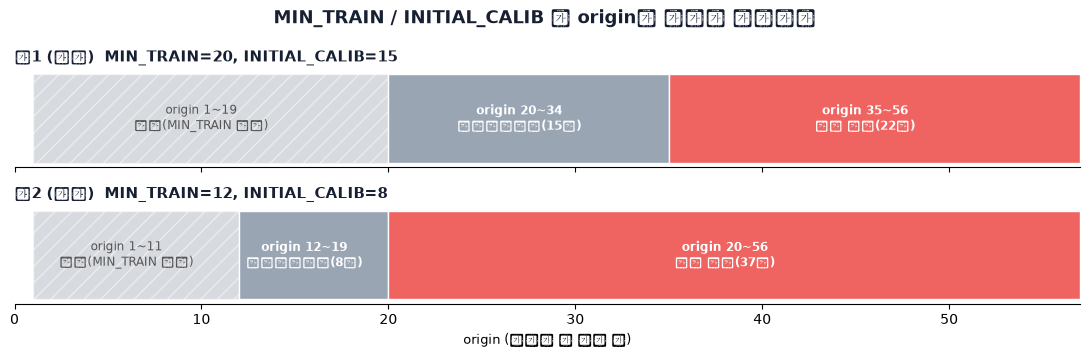

In [6]:
import matplotlib.pyplot as plt

GRAY, CALIB_COLOR, SCORE_COLOR = "#B0B6C0", "#9AA5B4", "#EF6461"
configs = [
    ("예1 (현재)  MIN_TRAIN=20, INITIAL_CALIB=15", 20, 15, 56),
    ("예2 (가상)  MIN_TRAIN=12, INITIAL_CALIB=8", 12, 8, 56),
]

fig, axes = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True)
for ax, (title, min_train, initial_calib, n_max) in zip(axes, configs):
    calib_end = min_train + initial_calib
    ax.barh(0, min_train - 1, left=1, height=0.6, color=GRAY, alpha=0.5, hatch="//", edgecolor="white")
    ax.barh(0, initial_calib, left=min_train, height=0.6, color=CALIB_COLOR, edgecolor="white")
    ax.barh(0, n_max - calib_end + 1, left=calib_end, height=0.6, color=SCORE_COLOR, edgecolor="white")
    ax.annotate(f"origin 1~{min_train-1}\n없음(MIN_TRAIN 미달)", xy=((1+min_train-1)/2, 0), ha="center", va="center", fontsize=8.5, color="#555")
    ax.annotate(f"origin {min_train}~{calib_end-1}\n캘리브레이션({initial_calib}개)", xy=((min_train+calib_end-1)/2, 0), ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
    ax.annotate(f"origin {calib_end}~{n_max}\n실제 채점({n_max-calib_end+1}개)", xy=((calib_end+n_max)/2, 0), ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
    ax.set_title(title, fontsize=10.5, fontweight="bold", color="#172033", loc="left")
    ax.set_yticks([])
    ax.set_xlim(0, n_max + 1)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

axes[-1].set_xlabel("origin (학습에 쓴 분기 수)", fontsize=9.5)
fig.suptitle("MIN_TRAIN / INITIAL_CALIB 이 origin을 어떻게 나누는가", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


### 2-2. origin을 늘리는 두 가지 방법

- **(A) `INITIAL_CALIB` 축소**: 저비용(기존 err_df 재사용), 캘리브레이션 풀만 작아짐
- **(B) `MIN_TRAIN` 축소**: 고비용(재백테스트 필요), 첫 origin 자체를 앞당김

In [7]:
# (A) INITIAL_CALIB 스윕 -- 이미 만든 err_df_target 재사용, 계산 빠름
calib_sweep_rows = []
for ic in [5, 10, 15, 20, 25]:
    r = run_variable_pipeline(TARGET_VAR, err_df_v=err_df_target, initial_calib=ic, verbose=False)
    e3_row = r["summary"][r["summary"]["_key"] == "E3"].iloc[0]
    best_row = r["summary"].iloc[0]
    calib_sweep_rows.append({
        "INITIAL_CALIB": ic,
        "캘리브레이션 풀 크기(origin수)": ic,
        "채점 origin 수": r["n_origins_scored"],
        "1위 모델": best_row["모델"],
        "1위 승률(%)": best_row["1위 비율(%)"],
        "E3 승률(%)": e3_row["1위 비율(%)"],
        "최종 선정": r["chosen"],
    })
calib_sweep_df = pd.DataFrame(calib_sweep_rows)
display(calib_sweep_df)


,INITIAL_CALIB,캘리브레이션 풀 크기(origin수),채점 origin 수,1위 모델,1위 승률(%),E3 승률(%),최종 선정
0,5,5,32,GP-Matern,43.2,19.2,GP-Matern
1,10,10,27,GP-Matern,34.4,31.2,E3(공용모델 유지)
2,15,15,22,GP-Matern,48.6,18.2,GP-Matern
3,20,20,17,GP-Matern,53.6,0.4,GP-Matern
4,25,25,12,GP-Matern,60.8,5.4,GP-Matern


`INITIAL_CALIB`을 줄이면 캘리브레이션 풀이 작아져 CRPS(리샘플링)/커버리지 추정이 노이즈에 민감해진다 -- 결과가 흔들리면 결론이 그만큼 불안정하다는 뜻.

In [8]:
# (B) MIN_TRAIN 축소 -- 실제 재백테스트 필요(naive/arima_aic 2개 모델만, 비용 절감)
import pmdarima as pm


def fc_naive(values, h=H):
    return np.repeat(values[-1], h)


def fc_arima_aic_diag(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    return np.asarray(m.predict(n_periods=h)), m.order


vals_target = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
quarters_target = raw[["quarter", TARGET_VAR]].dropna()["quarter"].tolist()
var_std_target = vals_target.std()

min_train_rows = []
for mt in [8, 12, 16, 20]:
    origins = list(range(mt, len(vals_target) - H + 1))
    first_order = None
    abs_errs = []
    for origin in origins:
        train, actual = vals_target[:origin], vals_target[origin:origin + H]
        fc_naive_v = fc_naive(train, H)
        try:
            fc_arima_v, order = fc_arima_aic_diag(train, H)
        except Exception:
            fc_arima_v, order = fc_naive_v, None
        if first_order is None:
            first_order = order
        abs_errs.append(np.mean(np.abs(actual - fc_arima_v)) / var_std_target)
    min_train_rows.append({
        "MIN_TRAIN(분기)": mt, "MIN_TRAIN(년)": round(mt / 4, 1),
        "origin 개수": len(origins),
        "첫 origin 학습기간": f"{quarters_target[0]}~{quarters_target[mt - 1]}",
        "첫 origin ARIMA(AIC) 선택 order": str(first_order),
        "ARIMA 정규화 절대오차(평균)": round(np.mean(abs_errs), 4),
    })
min_train_df = pd.DataFrame(min_train_rows)
display(min_train_df)


,MIN_TRAIN(분기),MIN_TRAIN(년),origin 개수,첫 origin 학습기간,첫 origin ARIMA(AIC) 선택 order,ARIMA 정규화 절대오차(평균)
0,8,2.0,49,2011Q1~2012Q4,"(1, 0, 0)",0.5597
1,12,3.0,45,2011Q1~2013Q4,"(0, 1, 0)",0.5894
2,16,4.0,41,2011Q1~2014Q4,"(0, 1, 0)",0.5939
3,20,5.0,37,2011Q1~2015Q4,"(0, 2, 1)",0.6283


실제로는 `MIN_TRAIN`을 줄일수록(20→8) 오차가 오히려 **낮아진다**(0.63→0.56) -- 예상과 반대다.

원인: expanding window라 기존 origin들의 학습데이터는 그대로고, origin 8~19(2012~15년, 상대적으로 쉬운 시기)만 새로 추가돼 평균이 좋아 보이는 것. 즉 origin을 늘리면 평가가 엄격해지는 게 아니라 **낙관적으로 왜곡**될 수 있다 -- 어떤 시기가 추가되는지 먼저 확인해야 한다.

## 3. 정리 -- origin을 늘릴지 말지

| 방법 | 장점 | 단점 |
|---|---|---|
| (A) INITIAL_CALIB 축소 | 저비용, 채점origin↑ | 캘리브레이션 풀 축소로 노이즈 민감(`INITIAL_CALIB=10`에서 결론 뒤집힘) |
| (B) MIN_TRAIN 축소 | 검정력↑ | 재계산 비용 + 추가 origin 시기에 따라 왜곡 위험(실험에서 낙관적 왜곡 확인) |
| 데이터 자체 확장 | -- | 2010~11년 이전 데이터 없어 불가 |

**최종 판단**: `MIN_TRAIN=20, INITIAL_CALIB=15` 유지. 두 방법 다 "공짜로 더 안정적인 검증"이 아니라 다른 위험과 맞바꾸는 것이었고, 지금 값이 나쁘다는 증거도 없었다. 표본(origin 22~37개) 규모 대비 더 파는 건 수확체감이라 여기서 멈춘다.